## **US Visa Prediction Project**

### **Life cycle of Machine learning Project**

Understanding the Problem Statement

Data Collection

Exploratory data analysis

Data Cleaning

Data Pre-Processing

Model Training

Choose best model

## **About**

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on working place and maintain requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

1) Problem statement.
OFLC gives job certification applications for employers seeking to bring foreign workers into the United States and grants certifications.
As In last year the count of employees were huge so OFLC needs Machine learning models to shortlist visa applicants based on their previous data.
In this project we are going to use the data given to build a Classification model:

This model is to check if Visa get approved or not based on the given dataset.
This can be used to Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the certain criteria which influences the decision.
2) Data Collection.
The Dataset is part of Office of Foreign Labor Certification (OFLC)
The data consists of 25480 Rows and 12 Columns
https://www.kaggle.com/datasets/moro23/easyvisa-dataset

#### **2.1 Import Data and Required Packages**

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px 
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline 

#### **Importing and Head**

In [2]:
df = pd.read_csv("EasyVisa.csv")
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


#### **Shape of the dataset**

In [3]:
df.shape

(25480, 12)

In [4]:
df.describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


#### **Check Datatypes in the Dataset**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


## **EXPLORING THE DATA**

In [6]:
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

print("Numerical Columns :- " , len(numeric_features) , numeric_features)
print("Categorical Columns :- " , len(categorical_features) , categorical_features)

Numerical Columns :-  3 ['no_of_employees', 'yr_of_estab', 'prevailing_wage']
Categorical Columns :-  9 ['case_id', 'continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position', 'case_status']


In [7]:
# propotion of count data on categorical columns 
for col in categorical_features:
    print(df[col].value_counts(normalize=True) * 100)
    print("---------------------------------")

case_id
EZYV01       0.003925
EZYV16995    0.003925
EZYV16993    0.003925
EZYV16992    0.003925
EZYV16991    0.003925
               ...   
EZYV8492     0.003925
EZYV8491     0.003925
EZYV8490     0.003925
EZYV8489     0.003925
EZYV25480    0.003925
Name: proportion, Length: 25480, dtype: float64
---------------------------------
continent
Asia             66.173469
Europe           14.646782
North America    12.919937
South America     3.343799
Africa            2.162480
Oceania           0.753532
Name: proportion, dtype: float64
---------------------------------
education_of_employee
Bachelor's     40.164835
Master's       37.810047
High School    13.422292
Doctorate       8.602826
Name: proportion, dtype: float64
---------------------------------
has_job_experience
Y    58.092622
N    41.907378
Name: proportion, dtype: float64
---------------------------------
requires_job_training
N    88.402669
Y    11.597331
Name: proportion, dtype: float64
---------------------------------
regio

## **Insights**

**case_id** have unique vlaues for each column which can be dropped as it it of no importance

**continent** column is highly biased towards asia. hence we can combine other categories to form a single category.

**unit_of_wage** seems to be an important column as most of them are yearly contracts.

## **Univariate Analysis**

The term univariate analysis refers to the analysis of one variable prefix “uni” means “one.” The purpose of univariate analysis is to understand the distribution of values for a single variable.
Other Type of Analysis are

**Bivariate Analysis:** The analysis of two variables.

**Multivariate Analysis:** The analysis of two or more variables.

## Numerical Features

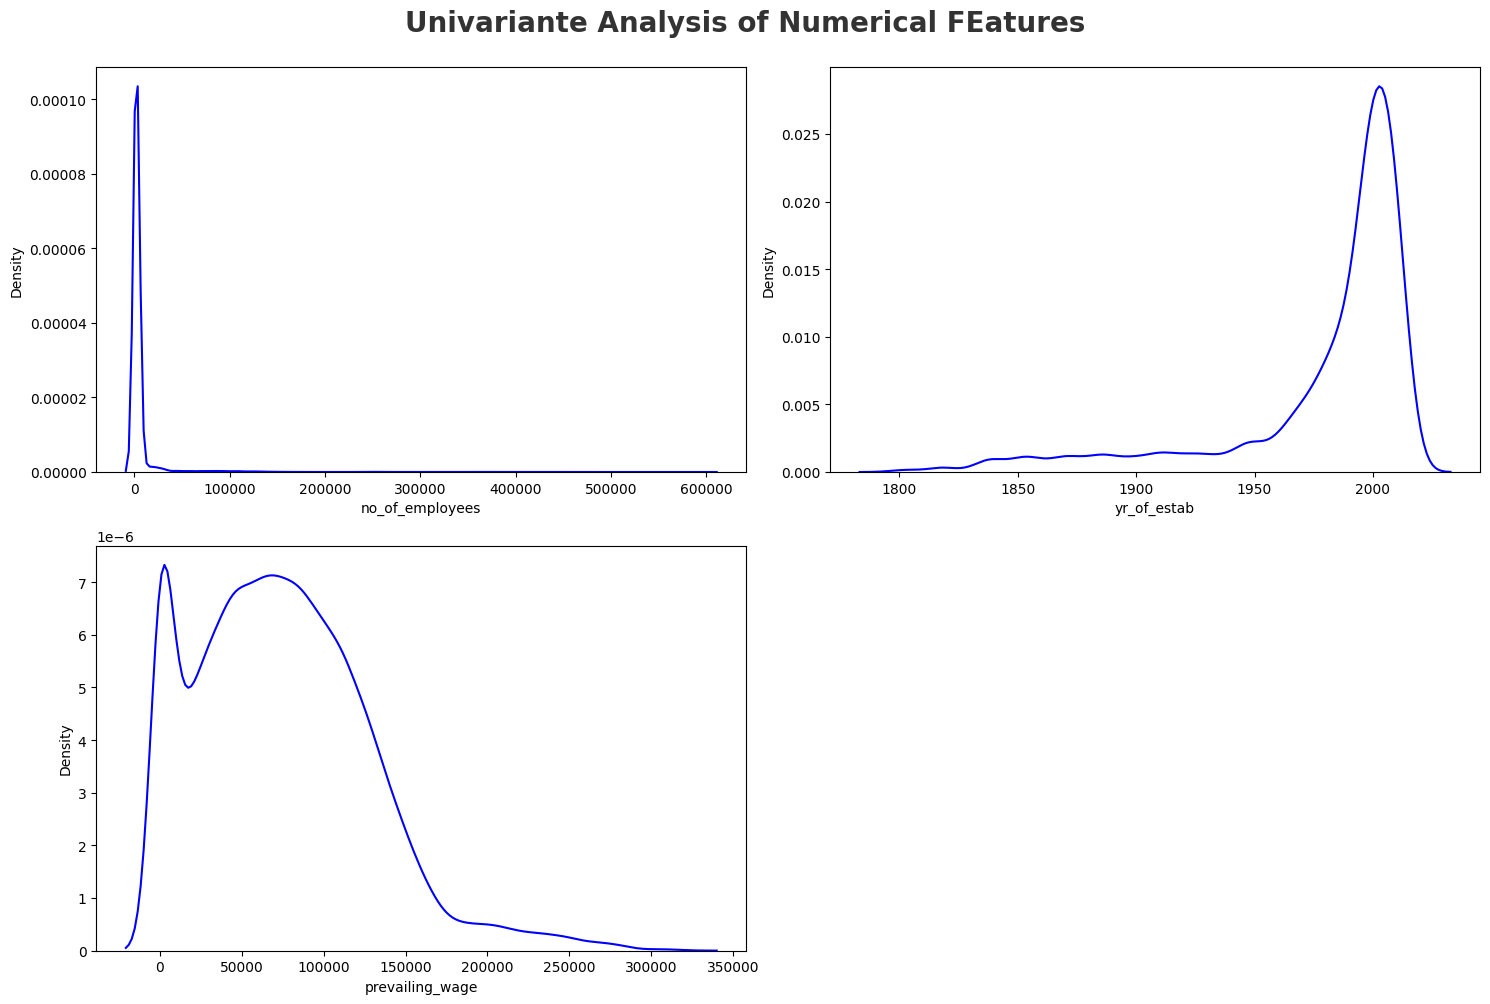

In [8]:
plt.figure(figsize=(15,10))
plt.suptitle("Univariante Analysis of Numerical FEatures" , fontsize = 20 , fontweight = 'bold' , alpha = 0.8 , y = 1.0)

for i in range(0 , len(numeric_features)):
    plt.subplot(2 , 2 , i + 1)
    sns.kdeplot(x = df[numeric_features[i]] , color='blue')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

##### **Insights**
**no_of_employees** column looks more skewed but it may be because of outlies.

**yr_of_estab** is a discrete feature.

**privailing-wage** is a right-skewed distribution.

## Categorical Features

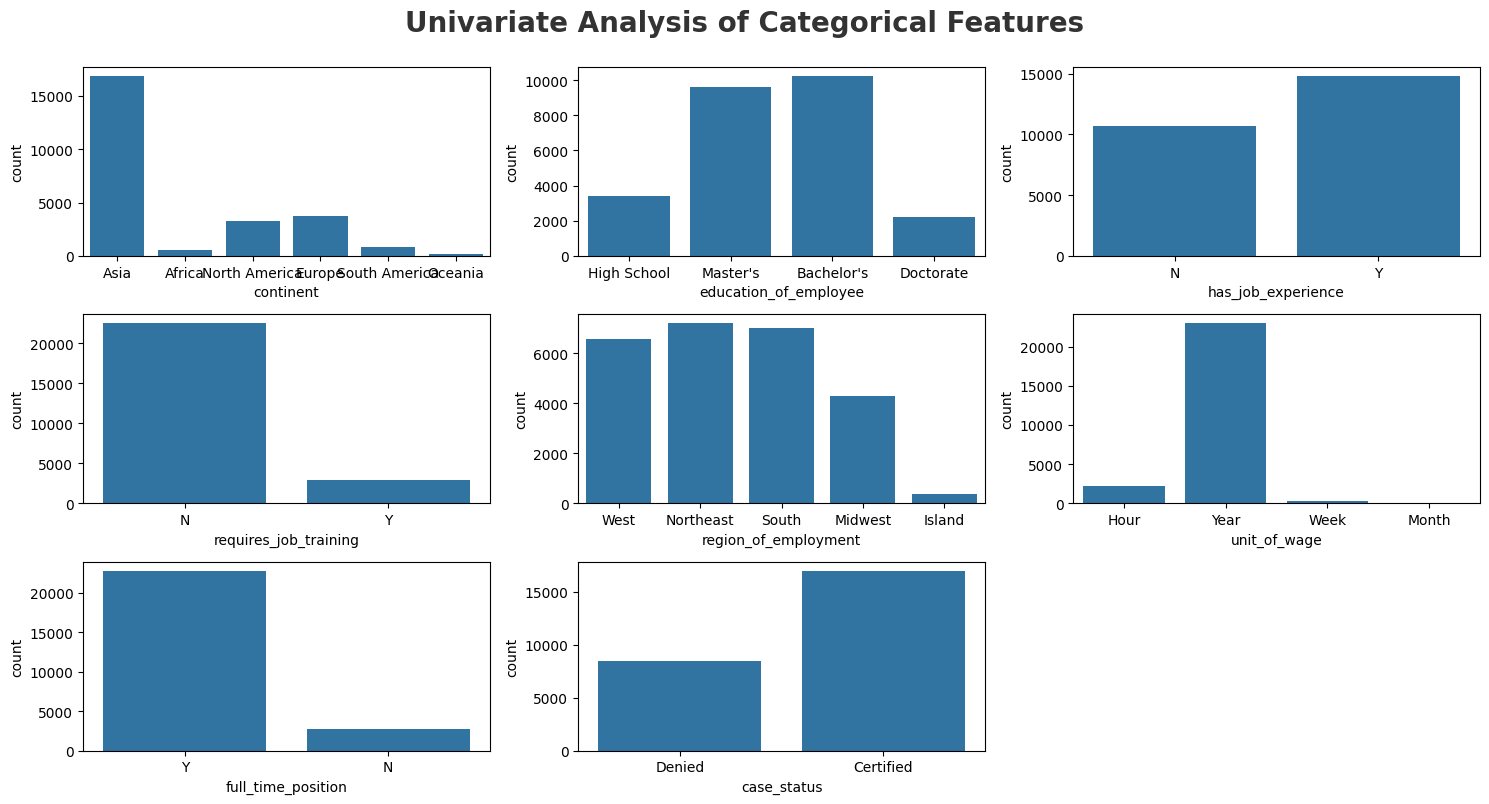

In [9]:
categorical_features.remove('case_id')
plt.figure(figsize=(15,8))
plt.suptitle("Univariate Analysis of Categorical Features" , fontsize = 20 , fontweight = 'bold' , alpha = 0.8 , y = 1.)

for i in range(0 , len(categorical_features)):
    plt.subplot(3 , 3 , i + 1)
    sns.countplot(x = df[categorical_features[i]])
    plt.xlabel(categorical_features[i])
    plt.tight_layout()

### **Insights**

*requires_job_training*, *unit_of_wage*, *full_time_position* and *continents* coulmns have signle category dominating.

In rest of the columns are balanced.

## Multivariate Analysis

In [10]:
discrete_features = [feature for feature in categorical_features if len(df[feature].unique()) <= 25]
continuous_features = [feature for feature in categorical_features if len(df[feature].unique()) > 25]

print("Discrete Features :- " , len(discrete_features) , discrete_features)
print("Continuous Features :- " , len(continuous_features) , continuous_features)

Discrete Features :-  8 ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position', 'case_status']
Continuous Features :-  0 []


## Check Multi Coliniarity in Numerical

In [11]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [12]:
df.corr(numeric_only=True)

,no_of_employees,yr_of_estab,prevailing_wage
no_of_employees,1.000000,-0.017770,-0.009523
yr_of_estab,-0.017770,1.000000,0.012342
prevailing_wage,-0.009523,0.012342,1.000000


**insights**

There is not multi coliniarity between the two numerical variables

## **Check Multicollinearity for Categorical features**
A **chi-squared test** (also chi-square or χ2 test) is a statistical hypothesis test that is valid to perform when the test statistic is chi-squared distributed under the null hypothesis, specifically Pearson's chi-squared test

A chi-square statistic is one way to show a relationship between two categorical variables.

Here we test correlation of Categorical columns with Target column i.e case_status

Null Hypothesis (
): The Feature is independent of target column (No-Correlation)

Alternative Hypothesis (
): The Feature and Target column are not independent (Correalted)

In [13]:
from scipy.stats import chi2_contingency
chi2_test = []
for feature in categorical_features:
    if chi2_contingency(pd.crosstab(df['case_status'] , df[feature]))[1] < 0.05:
        chi2_test.append('Rejected Null Hypothesis')
    else:
        chi2_test.append('Faile to Reject Null Hypothesis')

result = pd.DataFrame(data = [categorical_features , chi2_test]).T 
result.columns = ['Column' , 'Hypothesis Result']
result

,Column,Hypothesis Result
0,continent,Rejected Null Hypothesis
1,education_of_employee,Rejected Null Hypothesis
2,has_job_experience,Rejected Null Hypothesis
3,requires_job_training,Faile to Reject Null Hypothesis
4,region_of_employment,Rejected Null Hypothesis
5,unit_of_wage,Rejected Null Hypothesis
6,full_time_position,Rejected Null Hypothesis
7,case_status,Rejected Null Hypothesis


### **Check Null Values**

In [14]:
df.isnull().sum()

case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage             0
full_time_position       0
case_status              0
dtype: int64

In [15]:
continuous_features = [feature for feature in numeric_features if len(df[feature].unique()) >= 10]
print("Numerical Continuous Feature :- " , continuous_features)

Numerical Continuous Feature :-  ['no_of_employees', 'yr_of_estab', 'prevailing_wage']


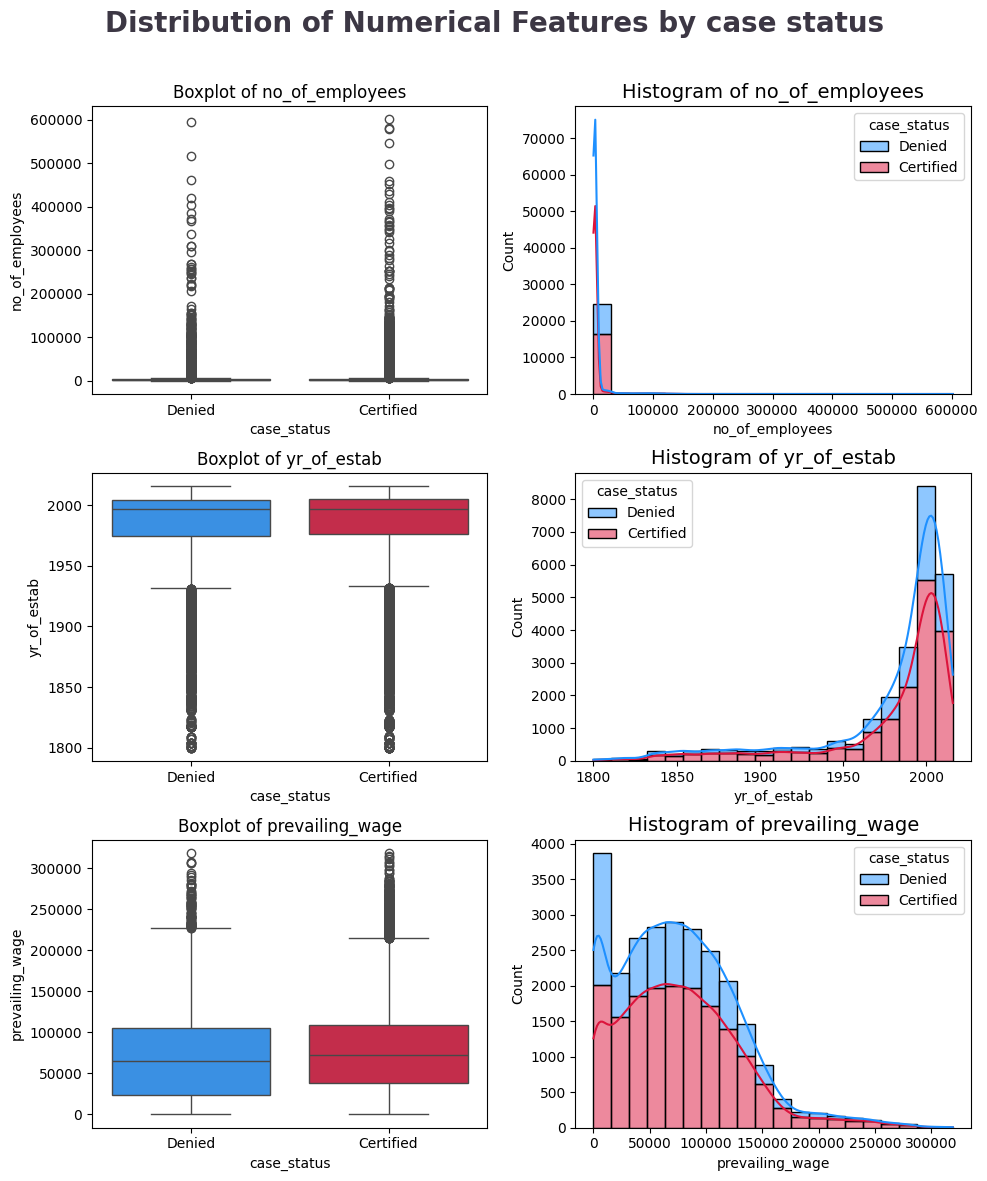

In [17]:

clr1 = ['#1E90FF', '#DC143C']

fig, ax = plt.subplots(3, 2, figsize=(10, 12))

fig.suptitle(
    "Distribution of Numerical Features by case status",
    color='#3C3744',
    fontsize=20,
    fontweight='bold',
    ha='center'
)

for i, col in enumerate(continuous_features):
    sns.boxplot(
        data=df,
        x='case_status',
        y=col,
        palette=clr1,
        ax=ax[i, 0]
    )

    ax[i, 0].set_title(f'Boxplot of {col}', fontsize=12)

    sns.histplot(
        data=df,
        x=col,
        hue='case_status',
        bins=20,
        kde=True,
        multiple='stack',
        palette=clr1,
        ax=ax[i, 1]
    )

    ax[i, 1].set_title(f'Histogram of {col}', fontsize=14)

fig.tight_layout()
fig.subplots_adjust(top=0.9)


## Visualization

#### **4.1 Visualize the Target Feature**

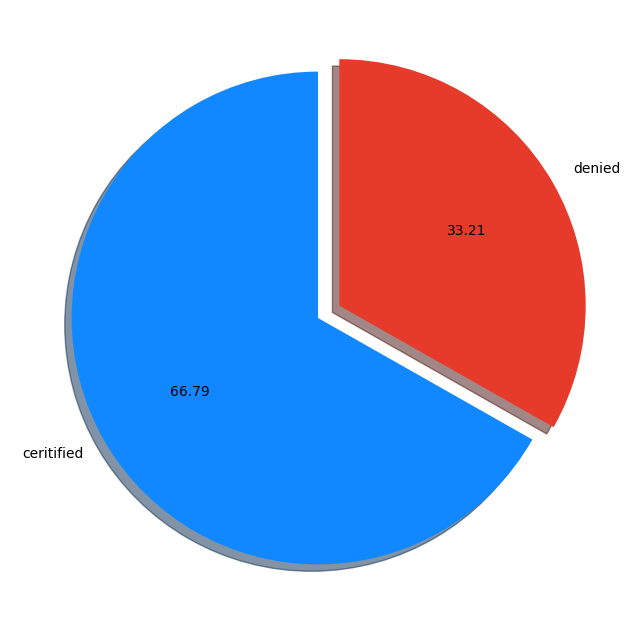

In [20]:
percentage = df.case_status.value_counts(normalize=True) * 100 
labels = ["ceritified" , 'denied']

fig , ax = plt.subplots(figsize = (15,8))
explode = (0,0.1)
colors = ['#1188ff' , '#e63a2a']
ax.pie(percentage , labels = labels , startangle = 90 , autopct = '%1.2f' , explode = explode , shadow = True , colors = colors)
plt.show()

#### **4.2: Does application continent has effect on visa status**

In [26]:
df.groupby("continent")['case_status'].value_counts(normalize=True).to_frame()*100

proportion
continent     case_status            
Africa        Certified     72.050817
              Denied        27.949183
Asia          Certified     65.310480
              Denied        34.689520
Europe        Certified     79.233655
              Denied        20.766345
North America Certified     61.877278
              Denied        38.122722
Oceania       Certified     63.541667
              Denied        36.458333
South America Certified     57.863850
              Denied        42.136150

In [37]:
(df.groupby('education_of_employee')['case_status']
   .value_counts(normalize=True)
   .to_frame() * 100).round(2)

proportion
education_of_employee case_status            
Bachelor's            Certified         62.21
                      Denied            37.79
Doctorate             Certified         87.23
                      Denied            12.77
High School           Denied            65.96
                      Certified         34.04
Master's              Certified         78.63
                      Denied            21.37